In [117]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [118]:
df=pd.read_csv('train (1).csv',usecols=['GarageQual','FireplaceQu','SalePrice'])

In [119]:
df.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [120]:
df.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

<Axes: xlabel='GarageQual'>

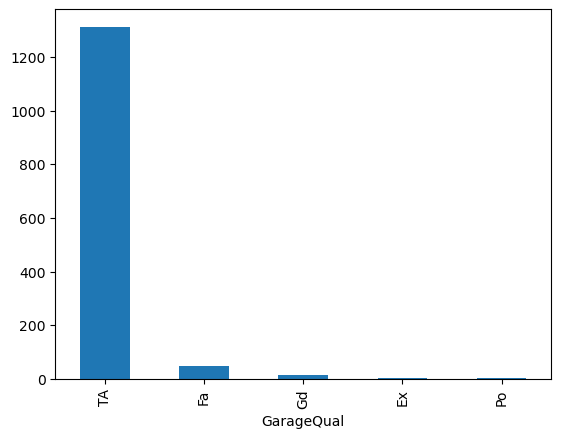

In [121]:
# Count the frequency of each unique category in the 'GarageQual' column,
# then plot those counts as a bar chart.
df['GarageQual'].value_counts().plot(kind='bar')

In [122]:
df['GarageQual'].mode()

0    TA
Name: GarageQual, dtype: object

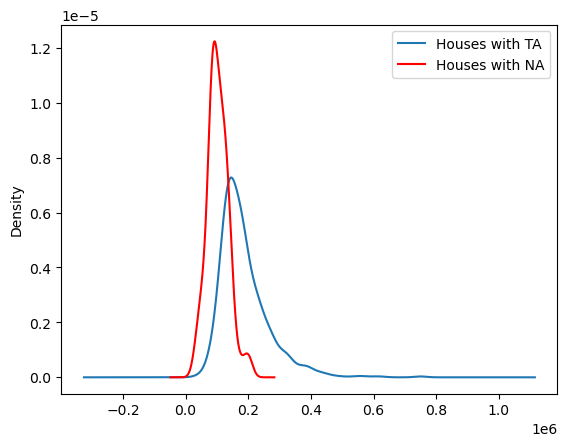

In [123]:
# we are plotting kde for those salesprices 
# whose garagequality is TA and is null

fig=plt.figure()
ax=fig.add_subplot(111)

df[df['GarageQual']=='TA']['SalePrice'].plot(kind='kde',ax=ax)
df[df['GarageQual'].isnull()]['SalePrice'].plot(kind='kde',ax=ax,color='red')
# ads legends
lines,labels=ax.get_legend_handles_labels()
labels=['Houses with TA','Houses with NA']
ax.legend(lines,labels,loc='best')
# ax.legend(loc='best')

In [124]:
temp=df[df['GarageQual']=='TA']['SalePrice']

In [125]:
# # we have replaced all missing values of garagequal with TA
# df['GarageQual'].fillna('TA',inplace=True)
# we have replaced all missing values of garagequal with TA
df['GarageQual'].fillna('Missing',inplace=True)

C:\Users\banik\AppData\Local\Temp\ipykernel_23756\2967661223.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['GarageQual'].fillna('Missing',inplace=True)


<Axes: xlabel='GarageQual'>

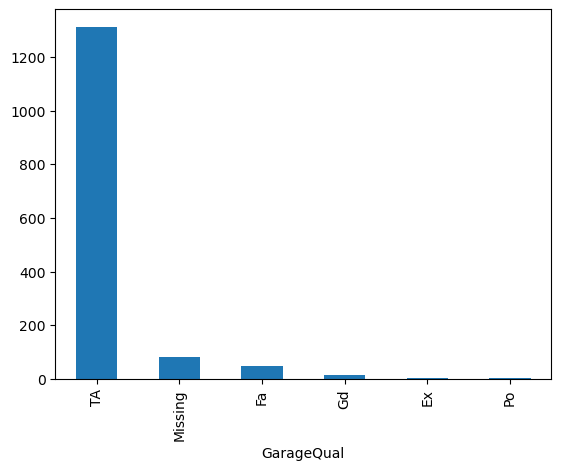

In [126]:
#frequency of TA after imputation
df['GarageQual'].value_counts().plot(kind='bar')

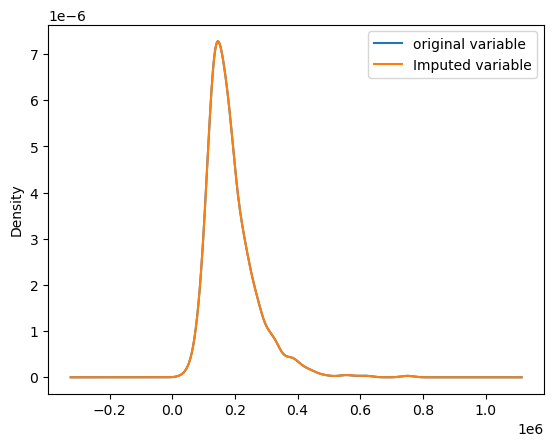

In [127]:
fig=plt.figure()
ax=fig.add_subplot(111)
temp.plot(kind='kde',ax=ax)

df[df['GarageQual']=='TA']['SalePrice'].plot(kind='kde',ax=ax)
# ads legends
lines,labels=ax.get_legend_handles_labels()
labels=['original variable','Imputed variable']
ax.legend(lines,labels,loc='best')
# ax.legend(loc='best')

# On FireplaceQu column

<Axes: xlabel='FireplaceQu'>

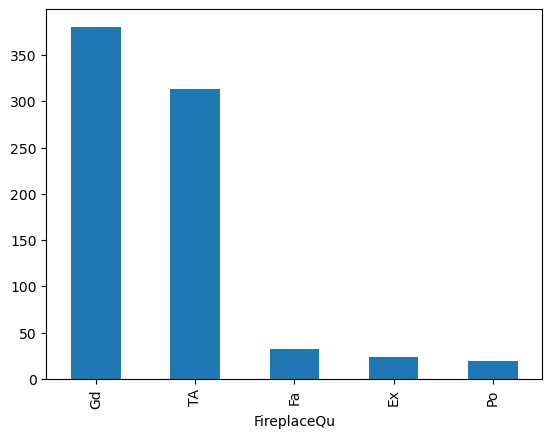

In [128]:
df['FireplaceQu'].value_counts().plot(kind='bar')

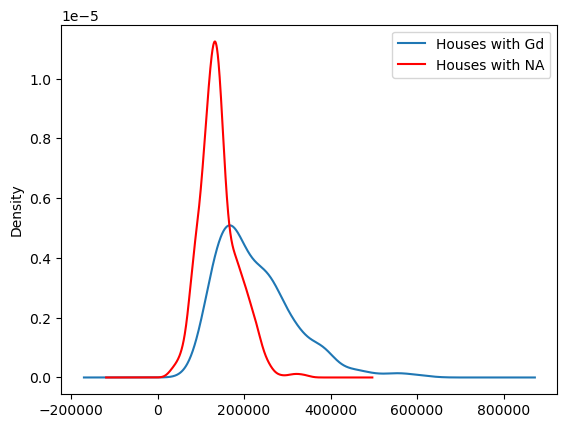

In [129]:

fig=plt.figure()
ax=fig.add_subplot(111)

df[df['FireplaceQu']=='Gd']['SalePrice'].plot(kind='kde',ax=ax)
df[df['FireplaceQu'].isnull()]['SalePrice'].plot(kind='kde',ax=ax,color='red')
# ads legends
lines,labels=ax.get_legend_handles_labels()
labels=['Houses with Gd','Houses with NA']
ax.legend(lines,labels,loc='best')
# ax.legend(loc='best')

In [130]:
temp = df[df['FireplaceQu']=='Gd']['SalePrice']

In [131]:
df['FireplaceQu'].fillna('Gd',inplace=True)

C:\Users\banik\AppData\Local\Temp\ipykernel_23756\891419280.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['FireplaceQu'].fillna('Gd',inplace=True)


<Axes: xlabel='FireplaceQu'>

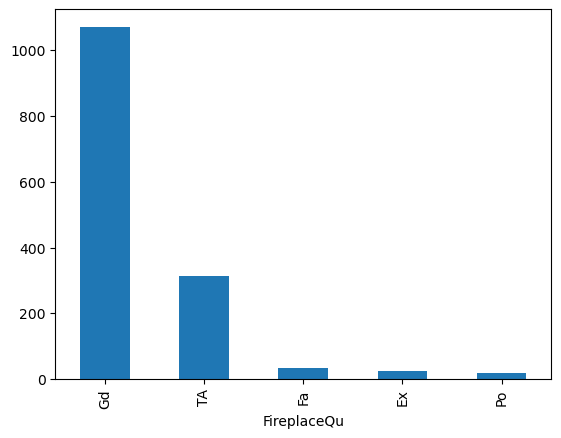

In [132]:
df['FireplaceQu'].value_counts().plot(kind='bar')

Text(0.5, 1.0, 'FireplaceQu')

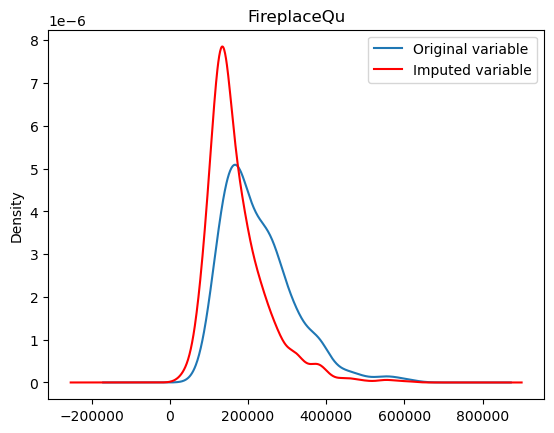

In [133]:
fig = plt.figure()
ax = fig.add_subplot(111)


temp.plot(kind='kde', ax=ax)

# distribution of the variable after imputation
df[df['FireplaceQu'] == 'Gd']['SalePrice'].plot(kind='kde', ax=ax, color='red')

lines, labels = ax.get_legend_handles_labels()
labels = ['Original variable', 'Imputed variable']
ax.legend(lines, labels, loc='best')

# add title
plt.title('FireplaceQu')

In [134]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.drop(columns=['SalePrice']),df['SalePrice'],test_size=0.2)

In [135]:
from sklearn.impute import SimpleImputer

In [136]:
# #applied only one strategy (most_frequent) for the whole X_train.
# imputer = SimpleImputer(strategy='most_frequent')
imputer = SimpleImputer(strategy='constant',fill_value='Missing')

In [137]:
# Fit the imputer on X_train (learn the most frequent values) 
# and transform X_train (replace missing values with learned values)
X_train = imputer.fit_transform(X_train)

# Use the already learned imputer (from training) 
# to transform X_test (so no data leakage happens from test set)
X_test = imputer.transform(X_test)


In [138]:
imputer.statistics_

array(['Missing', 'Missing'], dtype=object)